# 01 · From ratings to a defensible ranking
**Session A, 150 minutes including a break.** Guided lab: approximately 35 minutes after the worked lecture examples.

Learning outcomes: distinguish observations from missing values; reproduce a similarity and weighted prediction; build and compare three recommendation models; calculate ranking metrics; explain candidate eligibility and cold start.

**Part 1** is a guided lesson. **Part 2** is an independent final-project starting point. Real MovieLens results and synthetic course examples are labeled separately. The lecture’s slides 1–40 correspond to this notebook.

## Part 1 — Guided learning
### 1. Data card, provenance and appropriate use
MovieLens 100K contains 100,000 explicit 1–5 ratings from 943 users on 1,682 movies, collected September 1997–April 1998. The release removed users with fewer than 20 ratings or incomplete demographic information. It is therefore a selected historical sample, not a representation of all users today.

- `u.data`: user ID, movie ID, stars, Unix timestamp. The rating is a response after exposure, not a randomized preference label.
- `u.item`: title, release metadata, URL and 19 genre indicators. Genres can overlap.
- `u.user`: legacy age, gender, occupation and ZIP fields. These are **not default model features**, and do not establish richer identity categories.
- No impression positions, logging propensities, provider ownership, accessibility needs, well-being outcomes or consent records are present.

Source: [GroupLens](https://grouplens.org/datasets/movielens/100k/). Citation: Harper & Konstan (2015), *The MovieLens Datasets: History and Context*, DOI [10.1145/2827872](https://doi.org/10.1145/2827872).

The source README restricts redistribution and commercial use. The teaching ZIP supplies a downloader rather than the source records or individual processed records. Read the downloaded README before reuse or publication. The original host returned HTTP 503 during preparation; the local analysis used a public mirror, with counts/schema checked and file hashes recorded. Those checks do not establish independent official byte identity. The downloader tries the original host first.

In [1]:
from pathlib import Path  # Resolve the practical folder.
import sys, json  # Import paths and JSON support.
import numpy as np  # Use arrays for calculations.
import pandas as pd  # Use labeled tables.
import matplotlib.pyplot as plt  # Create diagnostic figures.
from IPython.display import display  # Show notebook tables.
from threadpoolctl import threadpool_limits  # Keep laptop computations predictable.
ROOT = Path.cwd()  # Start from the current directory.
if not (ROOT / 'src').is_dir():  # Support launching from notebooks/.
    ROOT = ROOT.parent  # Move to the project root.
assert (ROOT / 'src/recsys_lab.py').exists(), 'Open from the practical root or notebooks folder.'  # Check location.
sys.path.insert(0, str(ROOT / 'src'))  # Make the teaching module importable.
from download_data import download  # Import the local downloader.
from recsys_lab import *  # Import the documented teaching functions.
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 12})  # Set readable plots.

In [2]:
raw_folder = download(ROOT)  # Download missing source files locally.
ratings, movies, splits = prepare(ROOT)  # Validate and write chronological processed splits.
print('Ratings:', len(ratings), 'Users:', ratings.user_id.nunique(), 'Movies:', len(movies))  # Report size.
print('Observed density:', len(ratings) / (943 * 1682))  # Show how sparse the matrix is.
print('Source date range:', ratings.time_utc.min(), 'to', ratings.time_utc.max())  # Report time range.
print('Read usage conditions in:', raw_folder / 'README')  # Locate the source terms.

Source files available: /workspace/scratch/a78d3bf087d5/build/recsys-lecture/practical/data/raw/movielens-100k
Ratings: 100000 Users: 943 Movies: 1682
Observed density: 0.06304669364224531
Source date range: 1997-09-20 03:05:10+00:00 to 1998-04-22 23:10:38+00:00
Read usage conditions in: /workspace/scratch/a78d3bf087d5/build/recsys-lecture/practical/data/raw/movielens-100k/README


### 2. Visualize what was observed
A missing pair may mean unseen, unavailable, ignored, or not rated. Never fill a missing rating with a dislike merely because a dense array stores zero there.

**What to look for:** the star distribution, unequal activity across items, and the narrow historical collection period. These reveal data properties, not proof of unfair treatment. Rating count is not impression count.

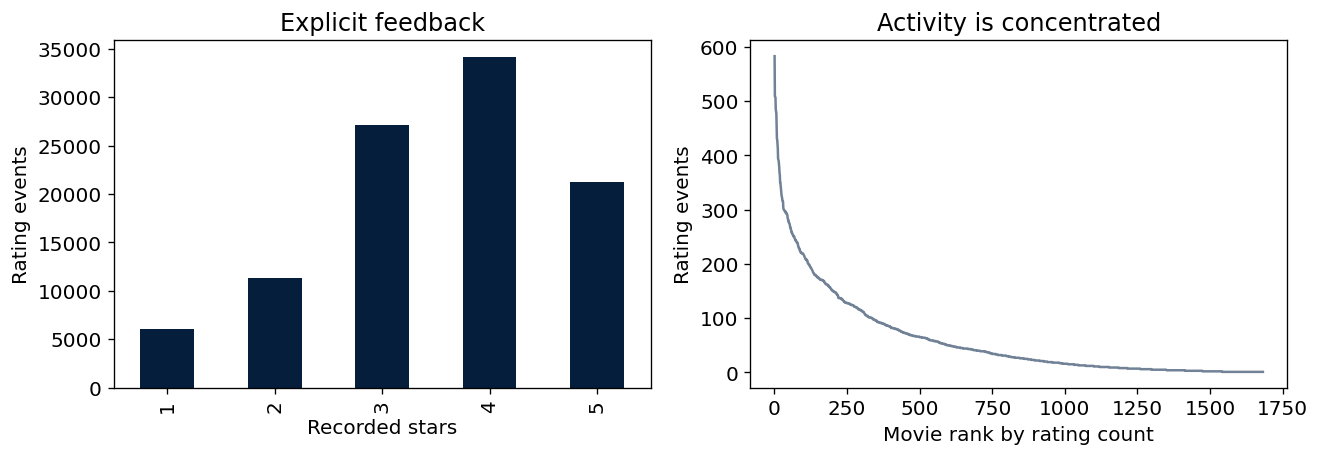

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # Compare feedback values and item activity.
ratings.rating.value_counts().sort_index().plot.bar(ax=axes[0], color='#041E3C')  # Count recorded stars.
axes[0].set(xlabel='Recorded stars', ylabel='Rating events', title='Explicit feedback')  # Label the first plot.
counts = ratings.groupby('item_id').size().sort_values(ascending=False)  # Count activity per movie.
axes[1].plot(np.arange(1, len(counts)+1), counts.to_numpy(), color='#718297')  # Plot the long tail.
axes[1].set(xlabel='Movie rank by rating count', ylabel='Rating events', title='Activity is concentrated')  # Label the second plot.
plt.tight_layout()  # Keep labels visible.
plt.show()  # Display the figure.

### 3. A small example that can be calculated by hand
All four rows are **students**, all six columns are learning resources. This is synthetic data, separate from MovieLens. C1=Python, C2=Statistics, C3=Machine learning, C4=Visualization, C5=Databases, C6=Data pipelines. Lina’s task is to rank C3, C5 and C6.

Use common observed resources C1, C2, C4 for user similarity. Raw cosine is $x\cdot y/(\|x\|\|y\|)$. Pearson first centers each vector **on those common items**. This is not the same as zero-filling and subtracting a full-history mean.

In [4]:
course = pd.read_csv(ROOT / 'data/raw/synthetic/course_ratings.csv').set_index('student')  # Load the exact slide matrix.
display(course)  # Keep blanks visible.
common = ['C1', 'C2', 'C4']  # Use resources rated by Lina and every comparison student.
a = course.loc['Lina', common].to_numpy(float)  # Extract Lina's shared ratings.
cosine = lambda x, y: float(x @ y / (np.linalg.norm(x) * np.linalg.norm(y)))  # Define normalized dot product.
rows = []  # Collect results for comparison.
for student in ['Omar', 'Maya', 'Noah']:  # Compare each other student.
    b = course.loc[student, common].to_numpy(float)  # Extract the same coordinates.
    rows.append([student, cosine(a, b), cosine(a-a.mean(), b-b.mean())])  # Compute raw and centered similarity.
similarities = pd.DataFrame(rows, columns=['student', 'cosine', 'co_rated_Pearson']).set_index('student')  # Label the table.
display(similarities.round(6))  # Check 0.976, 0.507, 0.989 raw cosines.

,C1,C2,C3,C4,C5,C6
student,,,,,,
Lina,5,4,NaN,1,NaN,NaN
Omar,4,5,5.0,1,2.0,3.0
Maya,1,2,2.0,5,5.0,1.0
Noah,5,4,4.0,2,3.0,4.0


,cosine,co_rated_Pearson
student,,
Omar,0.976190,0.884615
Maya,0.507093,-1.000000
Noah,0.989094,0.995871


In [5]:
neighbors = ['Noah', 'Omar']  # Choose two highest positive raw-cosine neighbors.
weights = similarities.loc[neighbors, 'cosine'].to_numpy()  # Preserve the same order as ratings.
predictions = {}  # Store one prediction for each candidate.
for item in ['C3', 'C5', 'C6']:  # Score only Lina's unrated resources.
    neighbor_ratings = course.loc[neighbors, item].to_numpy(float)  # Retrieve observed neighbor ratings.
    predictions[item] = float(weights @ neighbor_ratings / weights.sum())  # Calculate the weighted mean.
display(pd.Series(predictions, name='predicted_stars').sort_values(ascending=False))  # Expect C3, C6, C5.
assert np.isclose(predictions['C3'], 4.496717143862861)  # Check the slide arithmetic.

C3    4.496717
C6    3.503283
C5    2.503283
Name: predicted_stars, dtype: float64

**Interpretation:** the same weights yield C3≈4.497, C6≈3.503, C5≈2.503. These are predictions, not future truth. Raw cosine gives Maya a positive score despite opposite relative preferences, because all star ratings are positive. Pearson gives −1 for her shared pattern.

**Centered prediction:** choose positive Pearson weights. Add weighted neighbor deviations to Lina’s mean. Pairwise similarity uses common-item means; prediction offsets use each user’s complete observed-history mean. Declare these distinct conventions.

In [6]:
w = similarities.loc[neighbors, 'co_rated_Pearson'].to_numpy()  # Use positive centered similarities.
means = course.mean(axis=1)  # Compute each observed-history mean, skipping blanks.
deviations = course.loc[neighbors, 'C3'].to_numpy() - means.loc[neighbors].to_numpy()  # Remove rating habits.
centered = means.loc['Lina'] + w @ deviations / w.sum()  # Add the target user's mean back.
print('Centered C3 prediction:', centered)  # Expect approximately 4.294.

Centered C3 prediction: 4.293891326857984


### 4. Content features and a modern pipeline
A content model compares item descriptions with a profile. In the toy, Python=[1,0], Statistics=[0,1], ML=[1,1], DB=[1,0]. Using ratings ≥4 as positive history gives Lina’s profile 5[1,0]+4[0,1]=[5,4]. ML cosine≈.994 and DB cosine≈.781. This artificial feature map ignores prerequisites, language and accessibility.

A production system commonly separates **eligible catalog → candidate retrieval → scoring → re-ranking → display/logging**. CF or factorization can support retrieval and scoring; policy controls and safety rules also matter. [Google’s recommendation course](https://developers.google.com/machine-learning/recommendation/overview/types) provides the architecture overview.

**Check your understanding:** which stage could exclude a useful new resource before it ever receives a score? What evidence would be needed to show this is harmful to a learner?

In [7]:
profile = np.array([5., 4.])  # Represent the two topic preferences.
print('ML similarity:', cosine(profile, np.array([1., 1.])))  # Combine code and statistics.
print('DB similarity:', cosine(profile, np.array([1., 0.])))  # Compare code-only metadata.

ML similarity: 0.9938837346736188
DB similarity: 0.7808688094430304


### 5. Freeze the evaluation protocol
Global chronological split: earliest 80,000 events train, next 10,000 validation, final 10,000 test. Timestamp ties are ordered by user and item ID; time boundaries are non-decreasing. All model parameters below are predeclared teaching settings, not selected by repeated test evaluation. A project must tune only on validation, freeze its choices, refit train+validation and evaluate test once.

**Candidates:** items observed in the fitted period, minus the user’s already-rated items. Rank all remaining items, with deterministic ID tie-breaking. **Truth:** future test ratings ≥4. Recall’s denominator includes all known relevant test items, including items not in the fitted catalog. Users with zero positive test items are excluded from the ranking mean and counted separately. Rating-error metrics use all test ratings.

**Limit:** unknown relevance of unrated candidates means offline precision is a proxy. No actual availability dates or counterfactual exposure outcomes are recovered by this split.

In [8]:
split_table = pd.DataFrame([{'split': name, 'events': len(frame), 'first_time': frame.time_utc.min(), 'last_time': frame.time_utc.max()} for name, frame in splits.items()])  # Describe boundaries.
display(split_table)  # Check the time order.
fit_data = pd.concat([splits['train'], splits['validation']], ignore_index=True)  # Refit on the first 90%.
test_data = splits['test']  # Keep the final period for evaluation.

,split,events,first_time,last_time
0,train,80000,1997-09-20 03:05:10+00:00,1998-03-07 02:21:09+00:00
1,validation,10000,1998-03-07 02:21:09+00:00,1998-03-31 22:11:07+00:00
2,test,10000,1998-03-31 22:11:49+00:00,1998-04-22 23:10:38+00:00


### 6. Three transparent models
1. **Popularity:** rank by fitted rating count. For MAE/RMSE, predict a shrunk item mean `(sum + 20×global_mean)/(count+20)`; counts themselves are not star predictions.
2. **ItemKNN:** subtract user means; compute adjusted item cosine over common raters; require ≥3 common raters; multiply similarity by `overlap/(overlap+20)`; retain positive similarities; use at most 40 rated neighbors **for each target item**. Add the user mean back. No-neighbor fallback is that mean, or the global mean for a cold user.
3. **BiasedMF:** `global_mean + user_bias + item_bias + user_vector·item_vector`. Optimize squared error **only on observed pairs**, plus L2 penalties for biases/vectors. Use 12 factors, λ=10, seed 7, L-BFGS-B, maximum 1,000 iterations and a stated convergence tolerance. Check optimizer status rather than assuming convergence.

Read `src/recsys_lab.py` to see the full data loader, model and metric definitions. It intentionally exposes choices that production libraries may hide. [Koren et al. (2009)](https://doi.org/10.1109/MC.2009.263) explains factorization. The notebook is not a reproduction of that paper’s benchmark.

In [9]:
models = {}  # Store fitted models for inspection and caching.
metric_rows = []  # Collect comparable evaluation rows.
per_user_tables = {}  # Retain the distribution behind each average.
with threadpool_limits(limits=1):  # Avoid BLAS oversubscription on small matrices.
    for name, constructor in [('Popularity', Popularity), ('ItemKNN', ItemKNN), ('BiasedMF', BiasedMF)]:  # Use declared models.
        model = constructor().fit(fit_data)  # Fit from observed historical ratings.
        summary, per_user, recommended = evaluate(model, test_data)  # Evaluate the frozen test period.
        models[name] = model  # Keep the fitted object.
        per_user_tables[name] = per_user  # Keep user-level metrics locally.
        metric_rows.append({'model': name, **summary})  # Add one results row.
        np.savez_compressed(ROOT / f'data/processed/{name}_cache.npz', pred=model.pred, rank_scores=model.rank_scores, R=model.R)  # Cache locally.
        per_user.to_csv(ROOT / f'data/processed/{name}_per_user.csv', index=False)  # Save local processed audit data.
metrics = pd.DataFrame(metric_rows).set_index('model')  # Form the comparison table.
display(metrics.round(4))  # Compare ranking quality, star error and evaluation counts.
print('MF optimizer:', models['BiasedMF'].optimization)  # Verify optimization status.

MF optimizer: {'iterations': 183, 'success': True, 'message': 'CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH', 'loss': 67409.09076710574}


,RMSE,MAE,NDCG@10,Recall@10,Precision@10,evaluated_users,test_users,cold_test_users,cold_positive_events
model,,,,,,,,,
Popularity,1.0414,0.8507,0.2246,0.0799,0.2020,153,166,76,53
ItemKNN,1.1203,0.9332,0.0611,0.0123,0.0542,153,166,76,53
BiasedMF,1.0240,0.8242,0.1776,0.0624,0.1634,153,166,76,53


**How to read these results:** a popularity baseline can beat a personalized star-prediction model in a top-10 test. Do not replace an inconvenient result with an expected narrative. Inspect the ranking objective, neighbor coverage, rare-item scores, cold starts and candidate rules. Low RMSE and high NDCG are different aims.

The strict global time split yields many cold test users, while only a subset of the 943 users appears in the last period. The resulting numbers are a protocol-specific teaching result, not a leaderboard or a claim about all personalized systems.

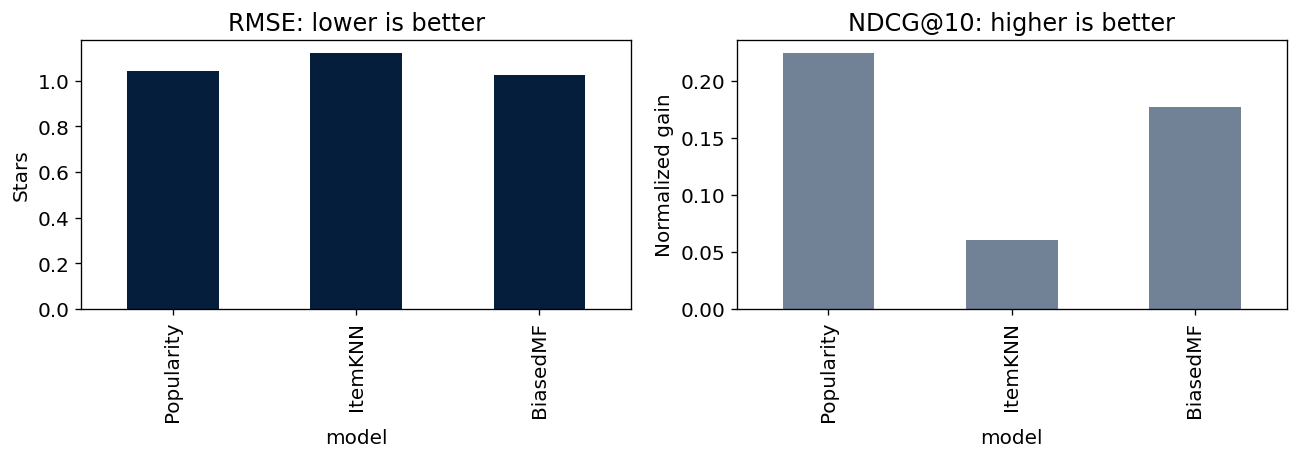

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # Separate lower-is-better and higher-is-better metrics.
metrics['RMSE'].plot.bar(ax=axes[0], color='#041E3C')  # Plot rating prediction errors.
axes[0].set(title='RMSE: lower is better', ylabel='Stars')  # Label the error scale.
metrics['NDCG@10'].plot.bar(ax=axes[1], color='#718297')  # Plot ranking quality.
axes[1].set(title='NDCG@10: higher is better', ylabel='Normalized gain')  # Label the ranking scale.
plt.tight_layout()  # Avoid label collisions.
plt.show()  # Display the figure.

### 7. Reproduce reported metric calculations
For stars `[5,4,1]` predicted as `[4,4,3]`, MAE=1 and RMSE=√(5/3)=1.291.

For a three-item recommendation with binary relevance `[1,0,1]` and two known relevant items: Precision@3=2/3, Recall@3=2/2. DCG=1+.5=1.5. The ideal order is `[1,1,0]`, so IDCG=1+1/log₂3=1.631, and NDCG=.920. **Do not normalize by an invented third positive.**

In [11]:
y = np.array([5., 4., 1.])  # Specify three true ratings.
yhat = np.array([4., 4., 3.])  # Specify their predictions.
print('MAE:', np.abs(y-yhat).mean(), 'RMSE:', np.sqrt(((y-yhat)**2).mean()))  # Compute both star metrics.
hits = np.array([1., 0., 1.])  # State the synthetic relevance order.
discounts = 1 / np.log2(np.arange(2, 5))  # Weight ranks 1, 2, 3.
precision = hits.mean()  # Divide hits by the displayed list length.
recall = hits.sum() / 2  # Divide hits by the two known relevant items.
ndcg = hits @ discounts / discounts[:2].sum()  # Normalize by the achievable ideal list.
print('P@3:', precision, 'R@3:', recall, 'NDCG@3:', ndcg)  # Reproduce the slides.

MAE: 1.0 RMSE: 1.2909944487358056
P@3: 0.6666666666666666 R@3: 1.0 NDCG@3: 0.9197207891481876


### 8. Inspect one recommendation locally
The next cell exposes the learner history and recommended titles, because aggregate results cannot explain a particular failure. Row-level outputs are omitted from the distributed notebook; run the cell locally after downloading the data. Do not publish user histories in your Git repository.

Questions: Are recommendations already seen? Is a high predicted star score supported by many neighbors? Did the model rank rare, poorly supported items highly? Would this list meet an explicitly stated user goal? A disliked title alone is not evidence of discrimination.

In [12]:
model = models['ItemKNN']  # Select the model to inspect.
uid = int(per_user_tables['ItemKNN'].query('history_count > 0').iloc[0].user_id)  # Choose an evaluated warm user.
history = fit_data[fit_data.user_id == uid].merge(movies[['item_id', 'title']], on='item_id')  # Join the local history.
ids = rank_all(model)[uid-1] + 1  # Convert internal item positions to source IDs.
recommendation = pd.DataFrame({'rank': np.arange(1, 11), 'item_id': ids, 'predicted_stars': model.pred[uid-1, ids-1]})  # Create the output table.
recommendation = recommendation.merge(movies[['item_id', 'title']], on='item_id', how='left').sort_values('rank')  # Add readable names.
display(history[['item_id', 'title', 'rating']].head(10))  # Inspect known preferences locally.
display(recommendation)  # Inspect the final unseen list locally.
assert not set(ids).intersection(set(history.item_id))  # Confirm already-rated items were excluded.

Row-level source-derived output omitted from this distributed copy. Rerun locally after source download.


### 9. Ethical checkpoint and student submission
Complete these sentences with evidence, not slogans:

- “The target estimates ___, whereas our user’s goal is ___.”
- “The candidate set can exclude ___ because ___.”
- “Our data cannot establish ___; we would need ___.”

**Lab submission:** one comparison table; the exact evaluation protocol and user counts; one inspected recommendation with its mechanism; two limitations. Be able to calculate one similarity and NDCG without an LLM.

## Part 2 — Final-project guidance and TODOs
### A. Define a question before changing code
Choose a specific context: learning resources, music discovery, marketplace items, or movies. Specify consumers, providers and the platform. Name one plausible lost benefit. Distinguish a hypothesis from a measured finding.

**TODO:** write a 150-word research question and data card. State whether the available data can actually test your harm claim. MovieLens alone cannot support a present-day hiring, disability or well-being conclusion.

### B. Establish a reproducible baseline
**TODO:** fit each chosen model on train only, choose settings on validation, freeze them, refit on train+validation, then evaluate test once. Record random seeds, package versions, candidate rules, relevance threshold and excluded users.

**Hints:** compare ItemKNN minimum overlap and shrinkage; consider a better ranking objective rather than increasing factor count blindly. If you inspect test results while developing, call this exploratory and reserve a new final evaluation window.

In [13]:
def project_validation_trial(train_frame, validation_frame, k=40, shrink=20):  # Provide a reusable validation scaffold.
    candidate_model = ItemKNN(k=k, shrink=shrink).fit(train_frame)  # Fit without future test data.
    result, _, _ = evaluate(candidate_model, validation_frame)  # Compare only on validation.
    return result  # Save the full protocol with the result.
# TODO: run a small predeclared grid on validation, freeze one setting, then evaluate test once.  # Do not execute a test-based search.

### C. Diagnose the surprising result
**TODO:** explain why the item-CF model performed poorly here. Inspect per-target overlap, fallback frequency, distribution of candidate scores, and the relevance of highly scored rare items. Try a candidate-support rule or a ranking-oriented objective on validation. Compare the new result with the same popularity baseline.

**Hint:** a rating estimator can assign high scores to poorly supported items. Penalizing uncertainty may help, but can also reduce visibility for new items. That tradeoff becomes an ethical question if it repeatedly blocks suitable opportunities.

### D. Add an extension with a meaningful ethical link
Pick one: content-based cold-start support; an accessible learning-resource metadata schema; a discovery control; a pairwise implicit-feedback model. BPR extension reading: [Rendle et al. (2009)](https://proceedings.mlr.press/r7/rendle09a.html). Implementing BPR is optional, not a hidden required baseline.

**TODO:** compare at least two plausible alternatives. Document what changes, who benefits, who might bear the cost, and what would falsify your hypothesis. Use Notebook 02 for the audit and recheck.

### E. Final report and assessment
1. Problem and stakeholders (15%).
2. Data provenance, target and limitations (20%).
3. Reproducible model and evaluation (25%).
4. Ethical diagnosis and tested remedy (25%).
5. Uncertainty, failures and clear communication (15%).

Submit code, environment instructions, a data-acquisition script, aggregate figures/tables and a report. Keep restricted raw data, individual histories and secrets out of Git. Disclose assistance from LLMs; demonstrate your own reasoning with a new hand calculation and an oral explanation of one failed recommendation.